# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [3]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = 1920 * 1080 * 3 * 1 / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 86400

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = 400 * frames_per_day * (1920 * 1080 * 3) / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = 400 * (10 * 86400) * (640 * 360 * 3) / (1024 ** 4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36-37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

Spatial: at 640x360 you're down to about 11% of the original pixels per frame, so something like a license
plate or a clear face is just gone, you can't un-blur detail that was never captured in the first place.
Temporal: at 10 fps a fast action (a punch, someone grabbing something) can happen entirely between two
frames you actually have, and tracking the same person frame-to-frame gets a lot harder since they can jump
much further in the gap between captures.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

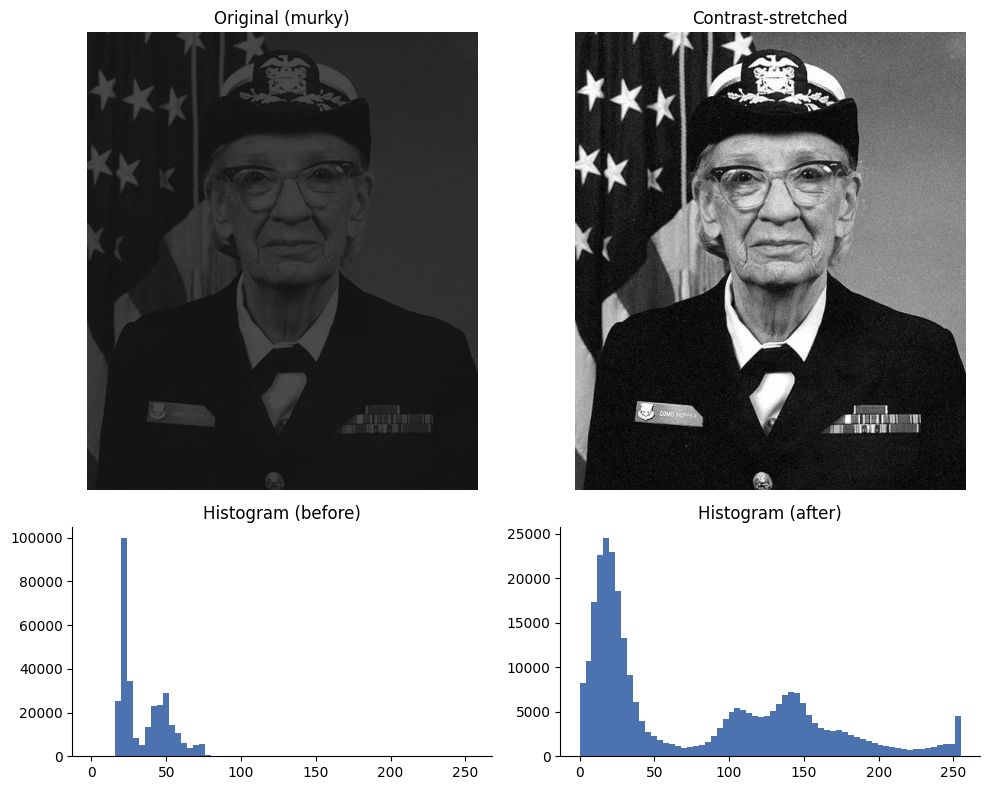

Contrast before: 0.609  ->  after: 1.000


In [4]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo) / (hi - lo) * 255, 0, 255)

lo2, hi2 = np.percentile(stretched, [1, 99])
c_after = michelson(hi2, lo2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original (murky)")
axes[0, 0].axis("off")

axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-stretched")
axes[0, 1].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="#4C72B0")
axes[1, 0].set_title("Histogram (before)")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="#4C72B0")
axes[1, 1].set_title("Histogram (after)")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** -- and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

It's a low-key histogram, everything bunched up dark and narrow instead of spread across the
full 0-255 range, which is why the raw image looks so murky (contrast before: 0.609). Stretching doesn't add
any new info, it just spreads that cramped range out to fill 0-255, so detail that was already there finally
becomes visible to our eyes (contrast after: ~1.0). Also
 a histogram alone could never tell you what's in the
image because it's just a count of intensity values, it throws away where those pixels actually sit. Two
totally different pictures can share the exact same histogram if they just happen to use the same set of
brightness values arranged differently.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: 68.7s - 78.1s
Running:  78.6s - 86.0s
Audio event at frame 2250 (t=75.0s)
Lighting event at frame 3000 (t=100.0s)


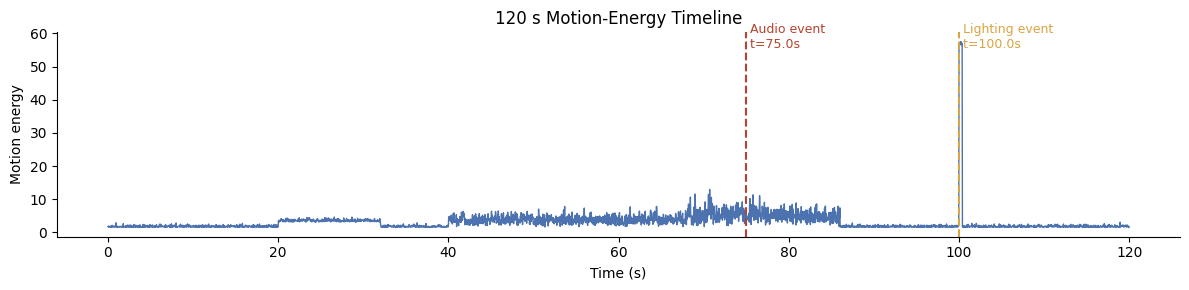

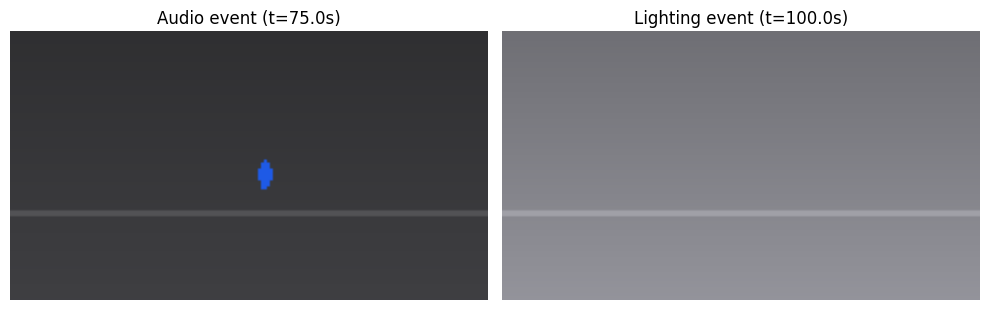

In [5]:
# TODO 1: person speed (px/s)
speed = np.sqrt(cctv.person_x.diff(FPS) ** 2 + cctv.person_y.diff(FPS) ** 2)

# TODO 2: standing / running time ranges (print the first and last time of each)
standing_times = cctv.time_s[speed < 3]
running_times = cctv.time_s[speed > 25]
print(f"Standing: {standing_times.min():.1f}s - {standing_times.max():.1f}s")
print(f"Running:  {running_times.min():.1f}s - {running_times.max():.1f}s")

# TODO 3: event frame indices
audio_event_idx = cctv.index[cctv.audio_level_db > -20][0]
lighting_event_idx = cctv.index[cctv.mean_brightness.diff() > 40][0]
print(f"Audio event at frame {audio_event_idx} (t={cctv.time_s[audio_event_idx]:.1f}s)")
print(f"Lighting event at frame {lighting_event_idx} (t={cctv.time_s[lighting_event_idx]:.1f}s)")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=1)
for idx, label, color in [(audio_event_idx, "Audio event", "#b5432e"),
                           (lighting_event_idx, "Lighting event", "#d9a441")]:
    t = cctv.time_s[idx]
    ax.axvline(t, color=color, ls="--")
    ax.text(t, ax.get_ylim()[1] * 0.92, f" {label}\n t={t:.1f}s", color=color, fontsize=9)
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy")
ax.set_title("120 s Motion-Energy Timeline")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, idx, label in zip(axes, [audio_event_idx, lighting_event_idx], ["Audio event", "Lighting event"]):
    frame = render_frame(cctv.iloc[idx])
    ax.imshow(frame); ax.axis("off")
    ax.set_title(f"{label} (t={cctv.time_s[idx]:.1f}s)")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

Uniform 20s keyframes (0, 20, 40, 60, 80, 100, 120) would've completely missed the audio event at 75s , it
falls right in the gap between 60 and 80. The lighting event at 100s would've been caught, but only by luck
since it happens to land right on a sample point. That's basically why content-based keyframe extraction
(Slide 40) wins here, it finds keyframes based on where stuff actually happens instead of sampling blindly
on a timer.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

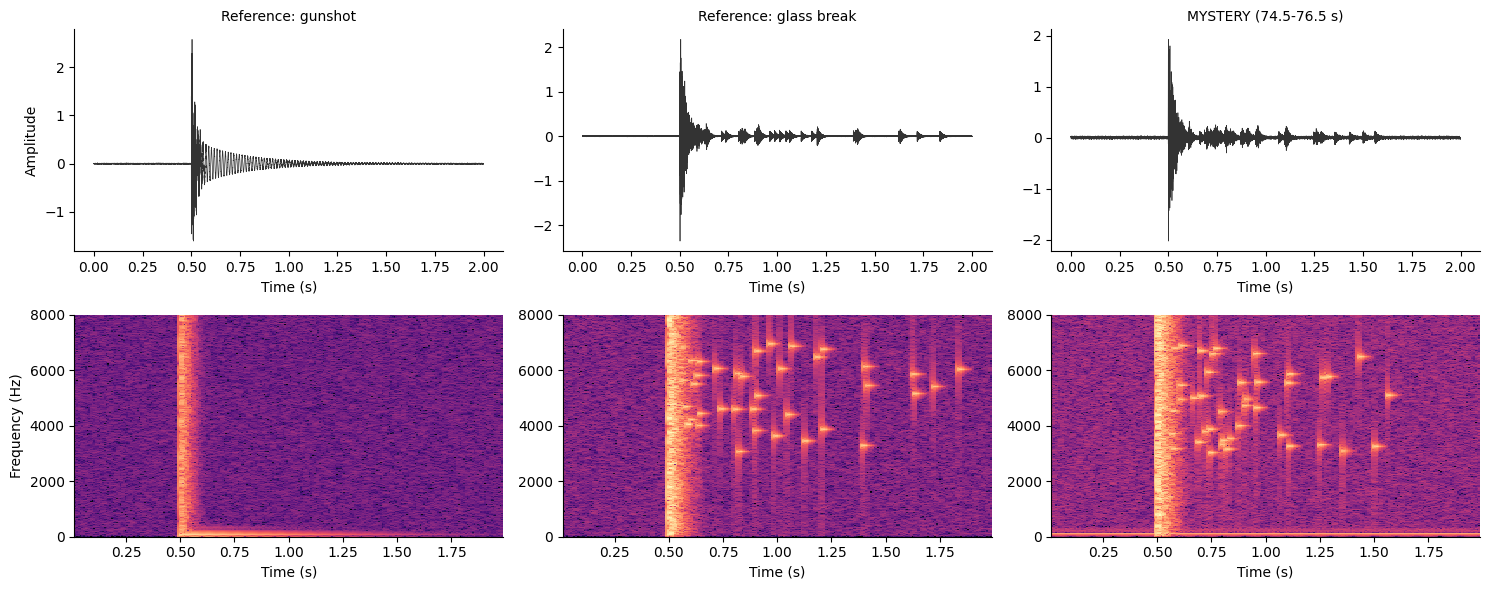

{'Reference: gunshot': 0.0032707914517922307, 'Reference: glass break': 0.9896168761000712, 'MYSTERY (74.5-76.5 s)': 0.8720794440036109}
VERDICT: the mystery sound is a GLASS BREAK (high-freq fraction: mystery=0.872, gunshot=0.003, glass=0.990)


In [6]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col, (name, x) in enumerate(clips.items()):
    t = np.arange(len(x)) / FS
    axes[0, col].plot(t, x, lw=0.5, color="#333333")
    axes[0, col].set_title(name, fontsize=10)
    axes[0, col].set_xlabel("Time (s)")
    if col == 0:
        axes[0, col].set_ylabel("Amplitude")

    f, tt, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    axes[1, col].pcolormesh(tt, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma")
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_xlabel("Time (s)")
    if col == 0:
        axes[1, col].set_ylabel("Frequency (Hz)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    t = np.arange(len(x)) / FS
    seg = x[(t >= 0.7) & (t < 1.7)]
    f, tt, Sxx = signal.spectrogram(seg, fs=FS, nperseg=512, noverlap=384)
    hf_mask = f > 3000
    hf_fraction[name] = float(Sxx[hf_mask].sum() / Sxx.sum())

print(hf_fraction)
# TODO 4: verdict
gun_hf, glass_hf, mystery_hf = (hf_fraction["Reference: gunshot"], hf_fraction["Reference: glass break"],
                                 hf_fraction["MYSTERY (74.5-76.5 s)"])
verdict = "GLASS BREAK" if abs(mystery_hf - glass_hf) < abs(mystery_hf - gun_hf) else "GUNSHOT"
print(f"VERDICT: the mystery sound is a {verdict} "
      f"(high-freq fraction: mystery={mystery_hf:.3f}, gunshot={gun_hf:.3f}, glass={glass_hf:.3f})")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

Honestly no, from the waveforms alone all three just show a spike around 0.5s, and raw amplitude doesn't
say anything about what made it. The spectrogram adds time, frequency, and magnitude all at once. What
actually decided it was the scattered high-frequency specks after the impact - glass break (and the mystery
clip) keep throwing off bursts above 3 kHz well after the hit, like glass fragments tinkling, while the
gunshot's high-frequency energy basically dies right after the crack. The numbers back it up: ~0.3% HF energy
for the gunshot reference, ~99.0% for glass, ~87.2% for the mystery clip, way closer to glass.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

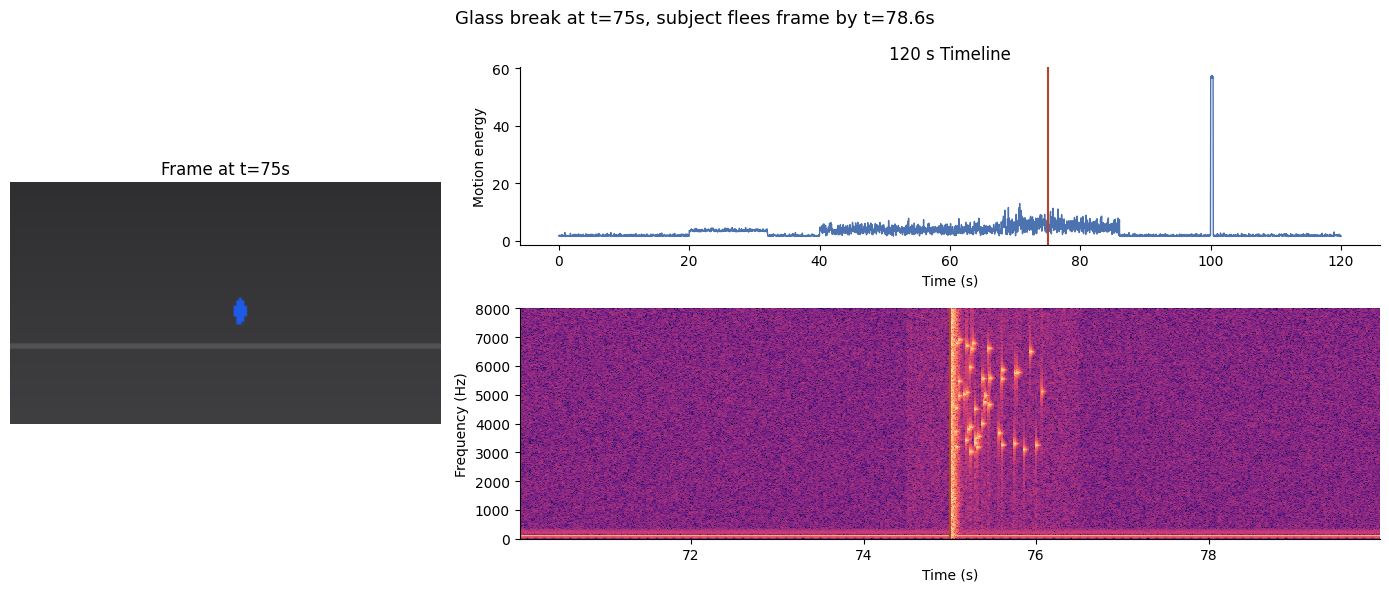

In [7]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4

# 1: the rendered video frame at t = 75 s (left)
idx_sel = (cctv.time_s - t_sel).abs().idxmin()
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[idx_sel]))
ax_frame.axis("off")
ax_frame.set_title(f"Frame at t={t_sel:.0f}s")

# 2: the full 120 s motion + audio timeline with a red marker at 75 s (top right)
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=1)
ax_timeline.axvline(t_sel, color="#b5432e", lw=1.5)
ax_timeline.set_xlabel("Time (s)"); ax_timeline.set_ylabel("Motion energy")
ax_timeline.set_title("120 s Timeline")

# 3: the spectrogram of x_audio (70-80 s) with the same marker (bottom right)
ax_spec = fig.add_subplot(gs[1, 1])
mask = (t_audio >= 70) & (t_audio < 80)
f, tt, Sxx = signal.spectrogram(x_audio[mask], fs=FS, nperseg=512, noverlap=384)
ax_spec.pcolormesh(70 + tt, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma")
ax_spec.axvline(t_sel, color="#b5432e", lw=1.5)
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlabel("Time (s)"); ax_spec.set_ylabel("Frequency (Hz)")

# 4: a conclusion-style figure title (what happened, not "Incident Dashboard")
fig.suptitle(f"Glass break at t=75s, subject flees frame by t=78.6s", fontsize=13)
plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

If the audio were 2s off, the marker at t=75s would still sit on the right video frame, but the spectrogram
panel would be showing silence instead of the burst, it'd look like the sound happened 2 seconds later than
it actually did, which could throw off exactly when someone thinks the person reacted. The spectrogram panel
is what gives it away: the burst just wouldn't line up under the marker anymore.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4-6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure -> pattern -> change -> event -> meaning, content-based keyframes,
  time x frequency x magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

Around 75.0s there's a loud glass-break sound, and by 78.6s the subject's gone from standing to running out
of frame, plus a quick lighting blip at 100.0s. I'd lead with the synchronized view (Task 5) over the raw
timeline or spectrogram alone, it ties the frame, the motion timeline, and the audio spectrogram to the
same timestamp, so nothing in the room needs to cross-reference separate charts to trust the story. For
storage, I'd go with the 640x360/10 fps policy for routine recording , it cuts the fleet from about
5,866 TB/day down to roughly 217 TB/day, a 27x saving, but that policy can't apply to cameras covering
entrances and exits, since you lose about 89% of per-frame pixel detail there, and that's exactly where
face- or plate-level ID evidence lives.